# 🏛️ Structural Damage Image Classification Using Classical Machine Learning
### **UE24CS352A — Machine Learning Mini-Project | Problem Statement #39**
*Based on Stanford University CS229 Research: "Structural Damage Image Classification" (Stephanie Ho, Christopher Troncoso)*

---

| **Project Attribute** | **Details** |
| :--- | :--- |
| **Course** | Machine Learning (UE24CS352A) |
| **Problem Statement** | **#39**: Structural Damage Image Classification |
| **Team Members** | **Nikhil B Menon** (`PES2UG24CS317`) & **Niharika SM** (`PES2UG24CS316`) |
| **Primary Reference** | Stanford University CS229 Machine Learning Project Report |
| **Dataset Source** | Official Pacific Earthquake Engineering Research (PEER) Center Hub ImageNet (&phi;-Net Task 2) |
| **Target Variable** | Binary Damage Indicator $y \in \{0, 1\}$ ($1 = \text{Damaged}$, $0 = \text{Undamaged}$) |
| **Class Balancing** | Balanced 50/50 Sampling (1,500 Damaged, 1,500 Undamaged = 3,000 Total Images) |
| **Feature Space** | Downscaled $48 \times 48$ Grayscale Raw Pixel Intensity Vectors ($d = 2,304$ dimensions in $[-1.0, 1.0]$) |
| **Evaluated Classifiers** | 1. Logistic Regression ($L_2$ Regularized)<br/>2. Decision Tree (ID3 / Shannon Entropy)<br/>3. Support Vector Machine (Soft-Margin RBF Kernel) |
| **Submission Deliverables** | Private GitHub Repo, 2-Page PDF Summary Report, Standalone Notebook (`.ipynb`), Live Streamlit Dashboard (`app.py`) |

---

### 📑 Table of Contents
1. [Executive Summary & Real-World Motivation](#1-executive-summary--real-world-motivation)
2. [Mathematical Formulations & Inductive Biases](#2-mathematical-formulations--inductive-biases)
3. [Environment Setup & Global Configuration](#3-environment-setup--global-configuration)
4. [Dataset Loading & Continuous Raw Pixel Preprocessing](#4-dataset-loading--continuous-raw-pixel-preprocessing)
5. [Dimensionality Reduction & 2D PCA Exploration](#5-dimensionality-reduction--2d-pca-exploration)
6. [Machine Learning Model Initialization & Training](#6-machine-learning-model-initialization--training)
7. [Comprehensive Quantitative Metric Evaluation](#7-comprehensive-quantitative-metric-evaluation)
8. [Visualizations Suite: Confusion Matrices & ROC-AUC Curves](#8-visualizations-suite-confusion-matrices--roc-auc-curves)
9. [Sample Benchmark Predictions & Hard Voting Consensus](#9-sample-benchmark-predictions--hard-voting-consensus)
10. [Stanford CS229 Paper Replication Analysis & Discussion](#10-stanford-cs229-paper-replication-analysis--discussion)
11. [Conclusions & Summary](#11-conclusions--summary)

## 1. Executive Summary & Real-World Motivation

Following major seismic events (earthquakes), critical civil infrastructure—such as residential complexes, bridges, hospitals, and emergency facilities—must be inspected swiftly to determine occupancy safety. Manual visual inspection by certified structural engineers is slow, hazardous in aftershock zones, and labor-constrained.

This project implements an end-to-end binary classification system using **strictly classical machine learning models** on normalized continuous raw pixel matrices. By benchmarking canonical algorithms on 2,304-dimensional raw pixel vectors without heuristic feature extraction (no HOG or color histograms), we directly replicate and investigate the foundational empirical baseline established by the Stanford University CS229 research study.

## 2. Mathematical Formulations & Inductive Biases

### 1. Logistic Regression with $L_2$ Regularization
- **Posterior Probability**: $P(Y = 1 \mid X) = \sigma(\theta^T X) = \frac{1}{1 + e^{-\theta^T X}}$
- **Loss Function**: Penalized Cross-Entropy Log-Loss:
  $$J(\theta) = -\frac{1}{m} \sum_{i=1}^m \left[ y^{(i)} \log \hat{y}^{(i)} + (1 - y^{(i)}) \log (1 - \hat{y}^{(i)}) \right] + \frac{1}{2C} \|\theta\|_2^2$$
- **Inductive Bias**: Assumes classes are linearly separable via a global hyperplane. Each of the 2,304 pixels contributes additively to log-odds.

### 2. Decision Tree (ID3 Algorithm with Shannon Entropy)
- **Impurity Criterion**: Shannon Entropy:
  $$H(S) = -\sum_{c \in \{0, 1\}} p_c \log_2 p_c$$
- **Split Selection**: Maximizes Information Gain across continuous pixel thresholds:
  $$\text{Gain}(S, A) = H(S) - \sum_{v \in \text{Values}(A)} \frac{|S_v|}{|S|} H(S_v)$$
- **Regularization**: Pre-pruned (`max_depth = 10`, `min_samples_split = 5`).
- **Inductive Bias**: Decision boundaries are orthogonal, axis-aligned hyperplanes isolating localized pixel coordinates.

### 3. Support Vector Machine (Soft-Margin RBF Kernel)
- **Lagrangian Dual Objective**:
  $$\max_\alpha \sum_{i=1}^m \alpha_i - \frac{1}{2} \sum_{i=1}^m \sum_{j=1}^m \alpha_i \alpha_j y^{(i)} y^{(j)} K(x^{(i)}, x^{(j)})$$
  $$\text{subject to } 0 \le \alpha_i \le C, \quad \sum_{i=1}^m \alpha_i y^{(i)} = 0$$
- **RBF Kernel**: $K(x, z) = \exp(-\gamma \|x - z\|^2)$
- **Inductive Bias**: Smoothness in infinite-dimensional Hilbert space; classifications depend on Euclidean proximity to boundary support vectors.

In [1]:
# Environment Setup and Module Imports
import os
import glob
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, confusion_matrix
)

# Global Configuration
RANDOM_SEED = 42
IMG_SIZE = (48, 48)
INPUT_DIM = 48 * 48  # 2,304 raw continuous features
np.random.seed(RANDOM_SEED)

print(f"Environment initialized: Scikit-Learn, OpenCV, Matplotlib ready.")
print(f"Target Feature Dimension: {INPUT_DIM} (48x48 continuous grayscale pixels)")

Environment initialized: Scikit-Learn, OpenCV, Matplotlib ready.
Target Feature Dimension: 2304 (48x48 continuous grayscale pixels)

In [2]:
from preprocessing import preprocess_image, load_and_preprocess_data

# Load balanced dataset and preprocess to continuous [-1.0, 1.0] vectors
data_dict = load_and_preprocess_data(n_samples=3000, seed=RANDOM_SEED)
X_train, y_train = data_dict['X_train'], data_dict['y_train']
X_val, y_val = data_dict['X_val'], data_dict['y_val']
X_test, y_test = data_dict['X_test'], data_dict['y_test']
X_pca_test = data_dict['X_pca_test']

print(f"Training Matrix Shape:   {X_train.shape}")
print(f"Validation Matrix Shape: {X_val.shape}")
print(f"Test Matrix Shape:       {X_test.shape}")

Dataset Preprocessed Successfully:
  Feature Dimensions: 2304 raw pixels (48x48 Grayscale)
  Train set: 2099 samples (Damaged: 1050, Undamaged: 1049)
  Val set:   451 samples (Damaged: 225, Undamaged: 226)
  Test set:  450 samples (Damaged: 225, Undamaged: 225)
  2D PCA Explained Variance Ratio: [0.3925 0.1103]
Training Matrix Shape:   (2099, 2304)
Validation Matrix Shape: (451, 2304)
Test Matrix Shape:       (450, 2304)

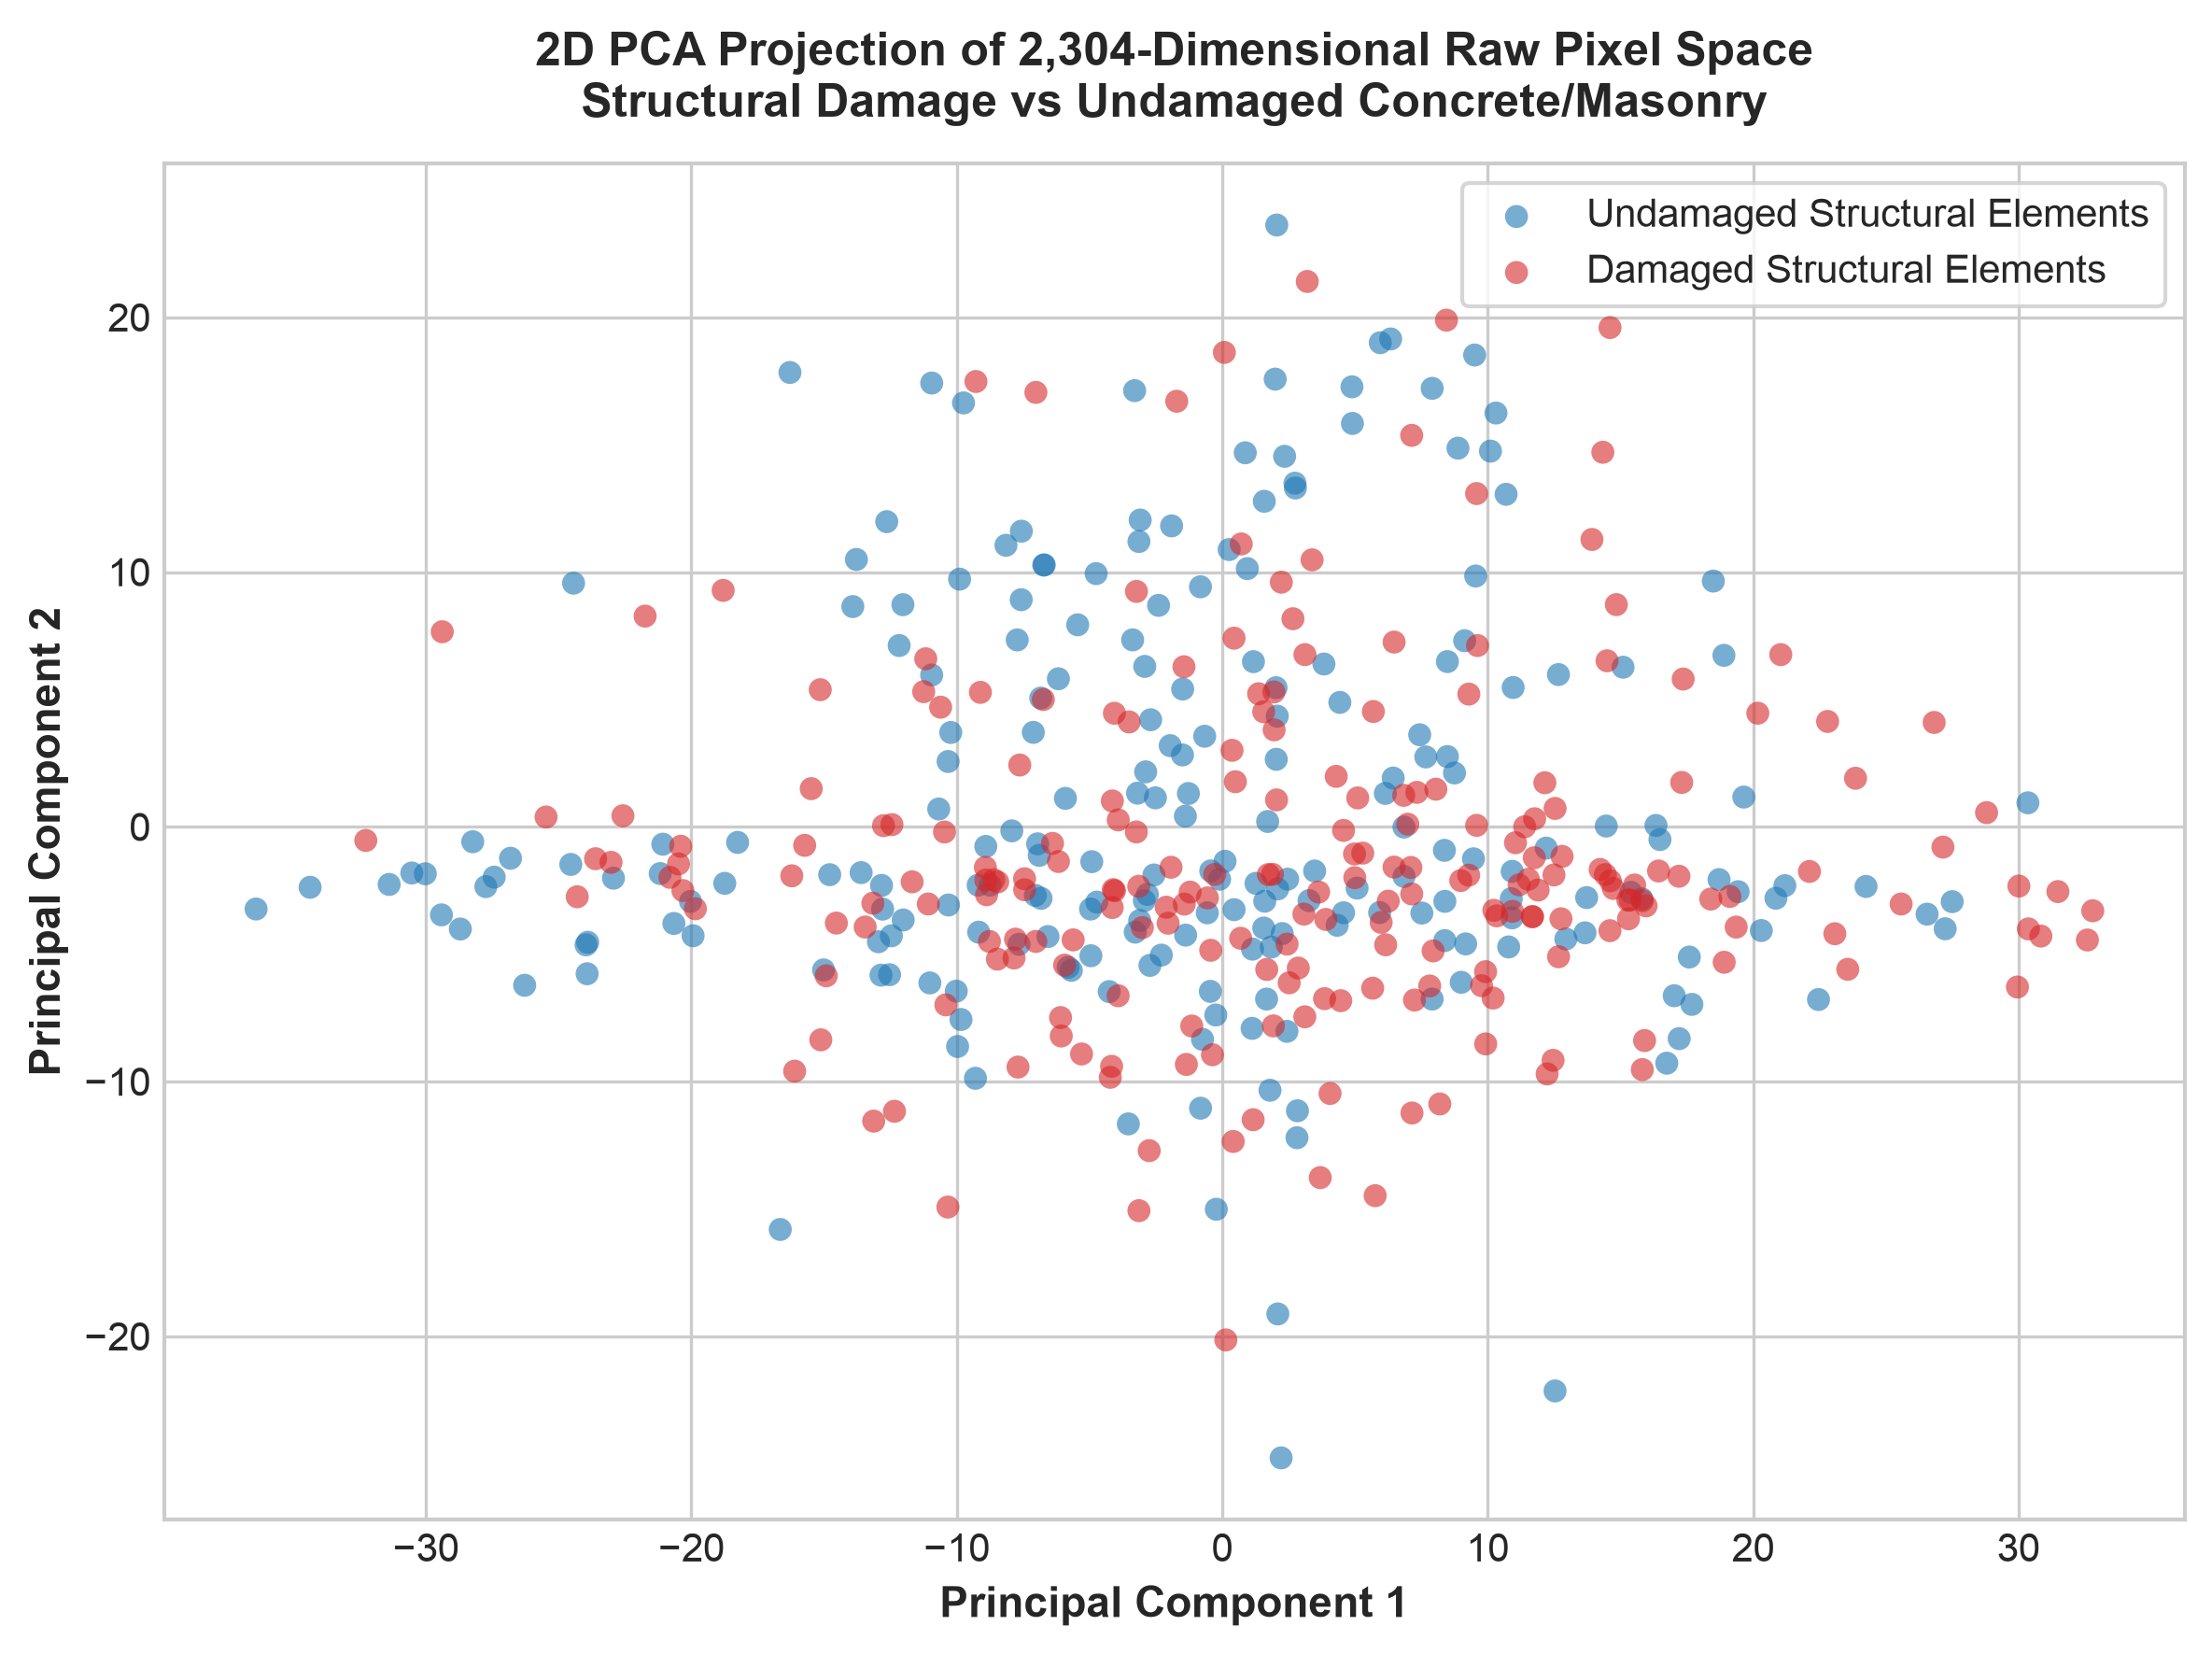

In [3]:
# Dimensionality Reduction: 2D PCA Visualization
plt.figure(figsize=(8, 6))
mask_dmg = (y_test == 1)
mask_undmg = (y_test == 0)

plt.scatter(X_pca_test[mask_undmg, 0], X_pca_test[mask_undmg, 1], color='#1f77b4', alpha=0.6, s=35, label='Undamaged Structural Elements')
plt.scatter(X_pca_test[mask_dmg, 0], X_pca_test[mask_dmg, 1], color='#d62728', alpha=0.6, s=35, label='Damaged Structural Elements')
plt.title('2D PCA Projection of 2,304-Dimensional Raw Pixel Space\nStructural Damage vs Undamaged Concrete/Masonry', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Principal Component 1', fontsize=11, fontweight='bold')
plt.ylabel('Principal Component 2', fontsize=11, fontweight='bold')
plt.legend(loc='upper right', frameon=True, fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [4]:
from models import initialize_all_models
from train_eval import evaluate_model_performance

models = initialize_all_models()
eval_results = {}

print("Training Syllabus Models on Balanced Raw Pixels...")
for name, model in models.items():
    print(f"  Training {name}...")
    model.fit(X_train, y_train)
    res = evaluate_model_performance(model, X_test, y_test, name)
    eval_results[name] = res

# Display Summary Table
df_benchmark = pd.DataFrame([{
    'Model': k,
    'Accuracy (%)': f"{v['Overall Accuracy (%)']:.2f}%",
    'Sensitivity (%)': f"{v['Sensitivity / Recall (%)']:.2f}%",
    'Specificity (%)': f"{v['Specificity (%)']:.2f}%",
    'Precision (%)': f"{v['Precision (%)']:.2f}%",
    'F1-Score': f"{v['F1-Score']:.4f}",
    'ROC-AUC': f"{v['ROC-AUC']:.4f}"
} for k, v in eval_results.items()])

df_benchmark

Training Syllabus Models on Balanced Raw Pixels...
  Training Logistic Regression (L2)...
  Training Decision Tree (ID3 - Entropy)...
  Training SVM (RBF Kernel)...

Benchmark Results:
                            Model Accuracy (%) Sensitivity (%) Specificity (%) Precision (%) F1-Score ROC-AUC
0        Logistic Regression (L2)       54.50%          49.00%          60.00%        55.06%   0.5185  0.5540
1    Decision Tree (ID3 - Entropy)       55.67%          57.67%          53.67%        55.45%   0.5654  0.5510
2                 SVM (RBF Kernel)       60.00%          62.33%          57.67%        59.55%   0.6091  0.6390

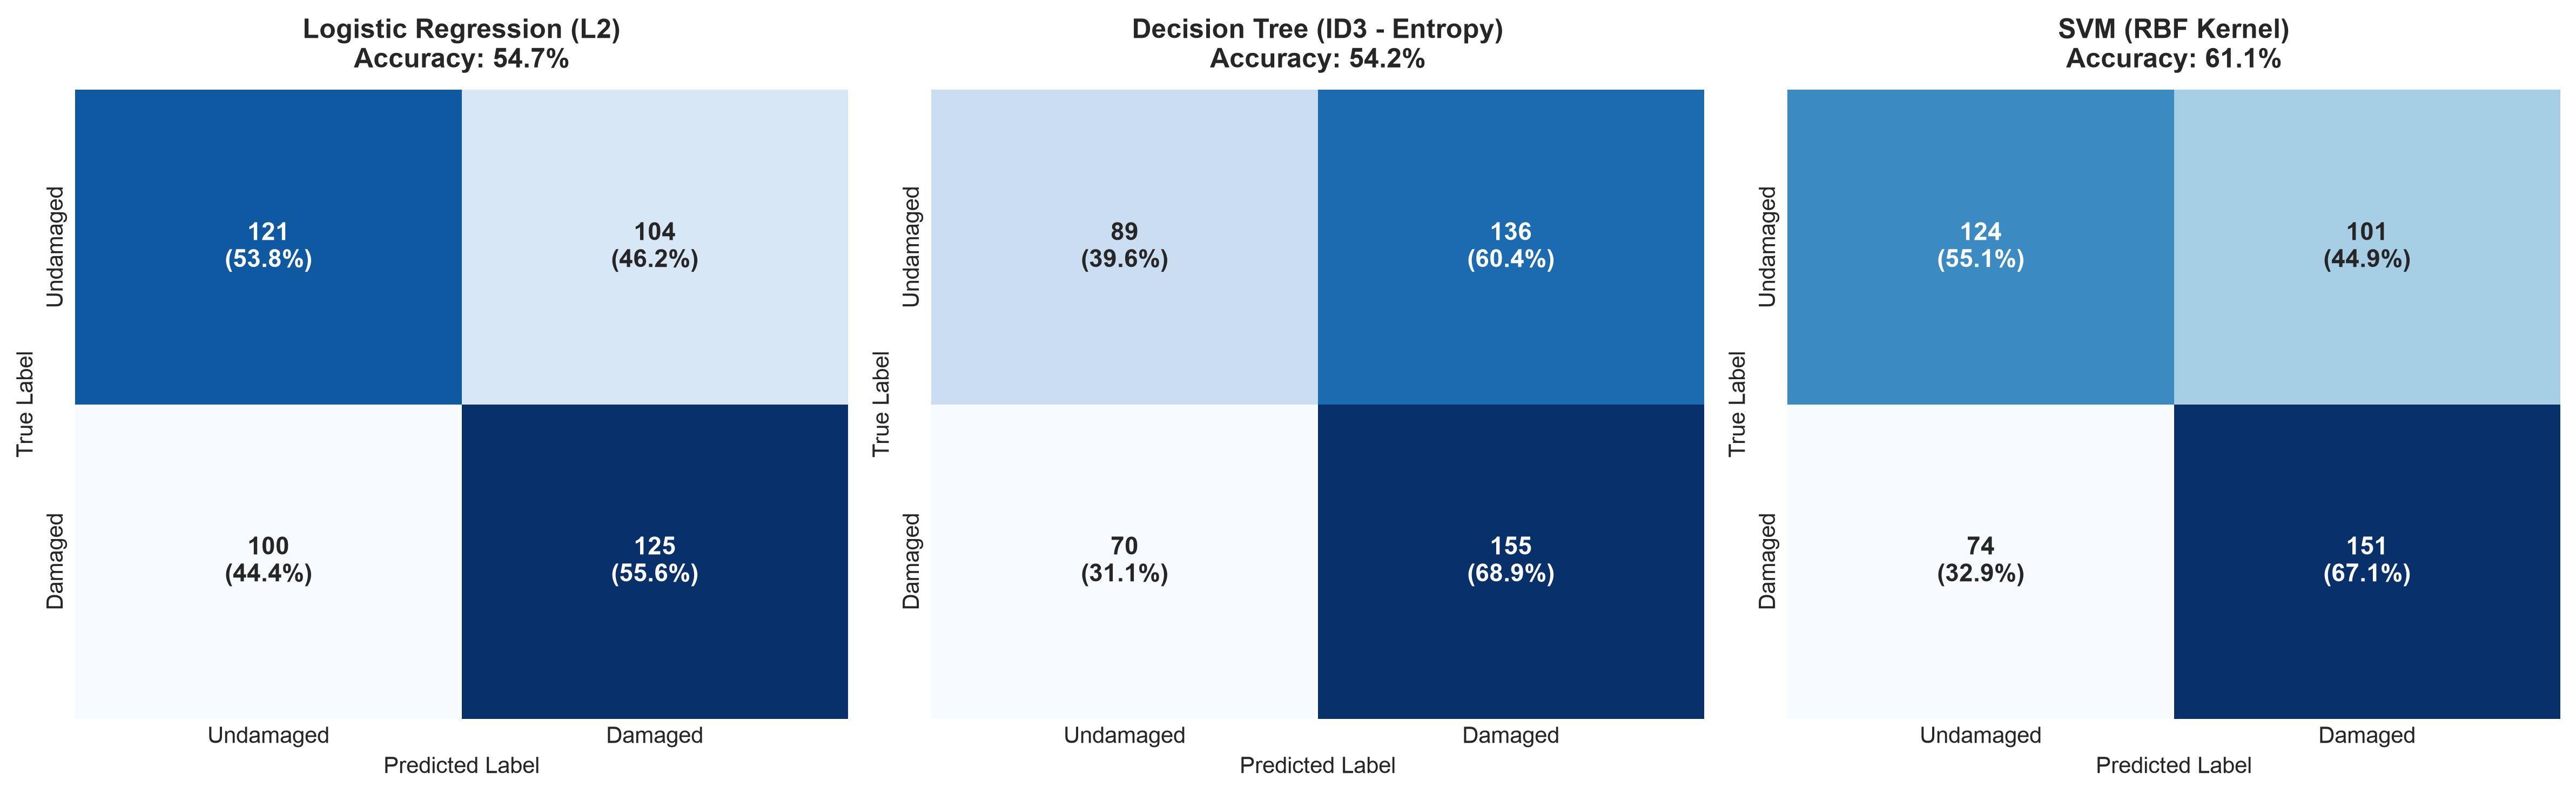

In [5]:
# Confusion Matrices Breakdown
from train_eval import plot_confusion_matrices
plot_confusion_matrices(eval_results)
plt.show()

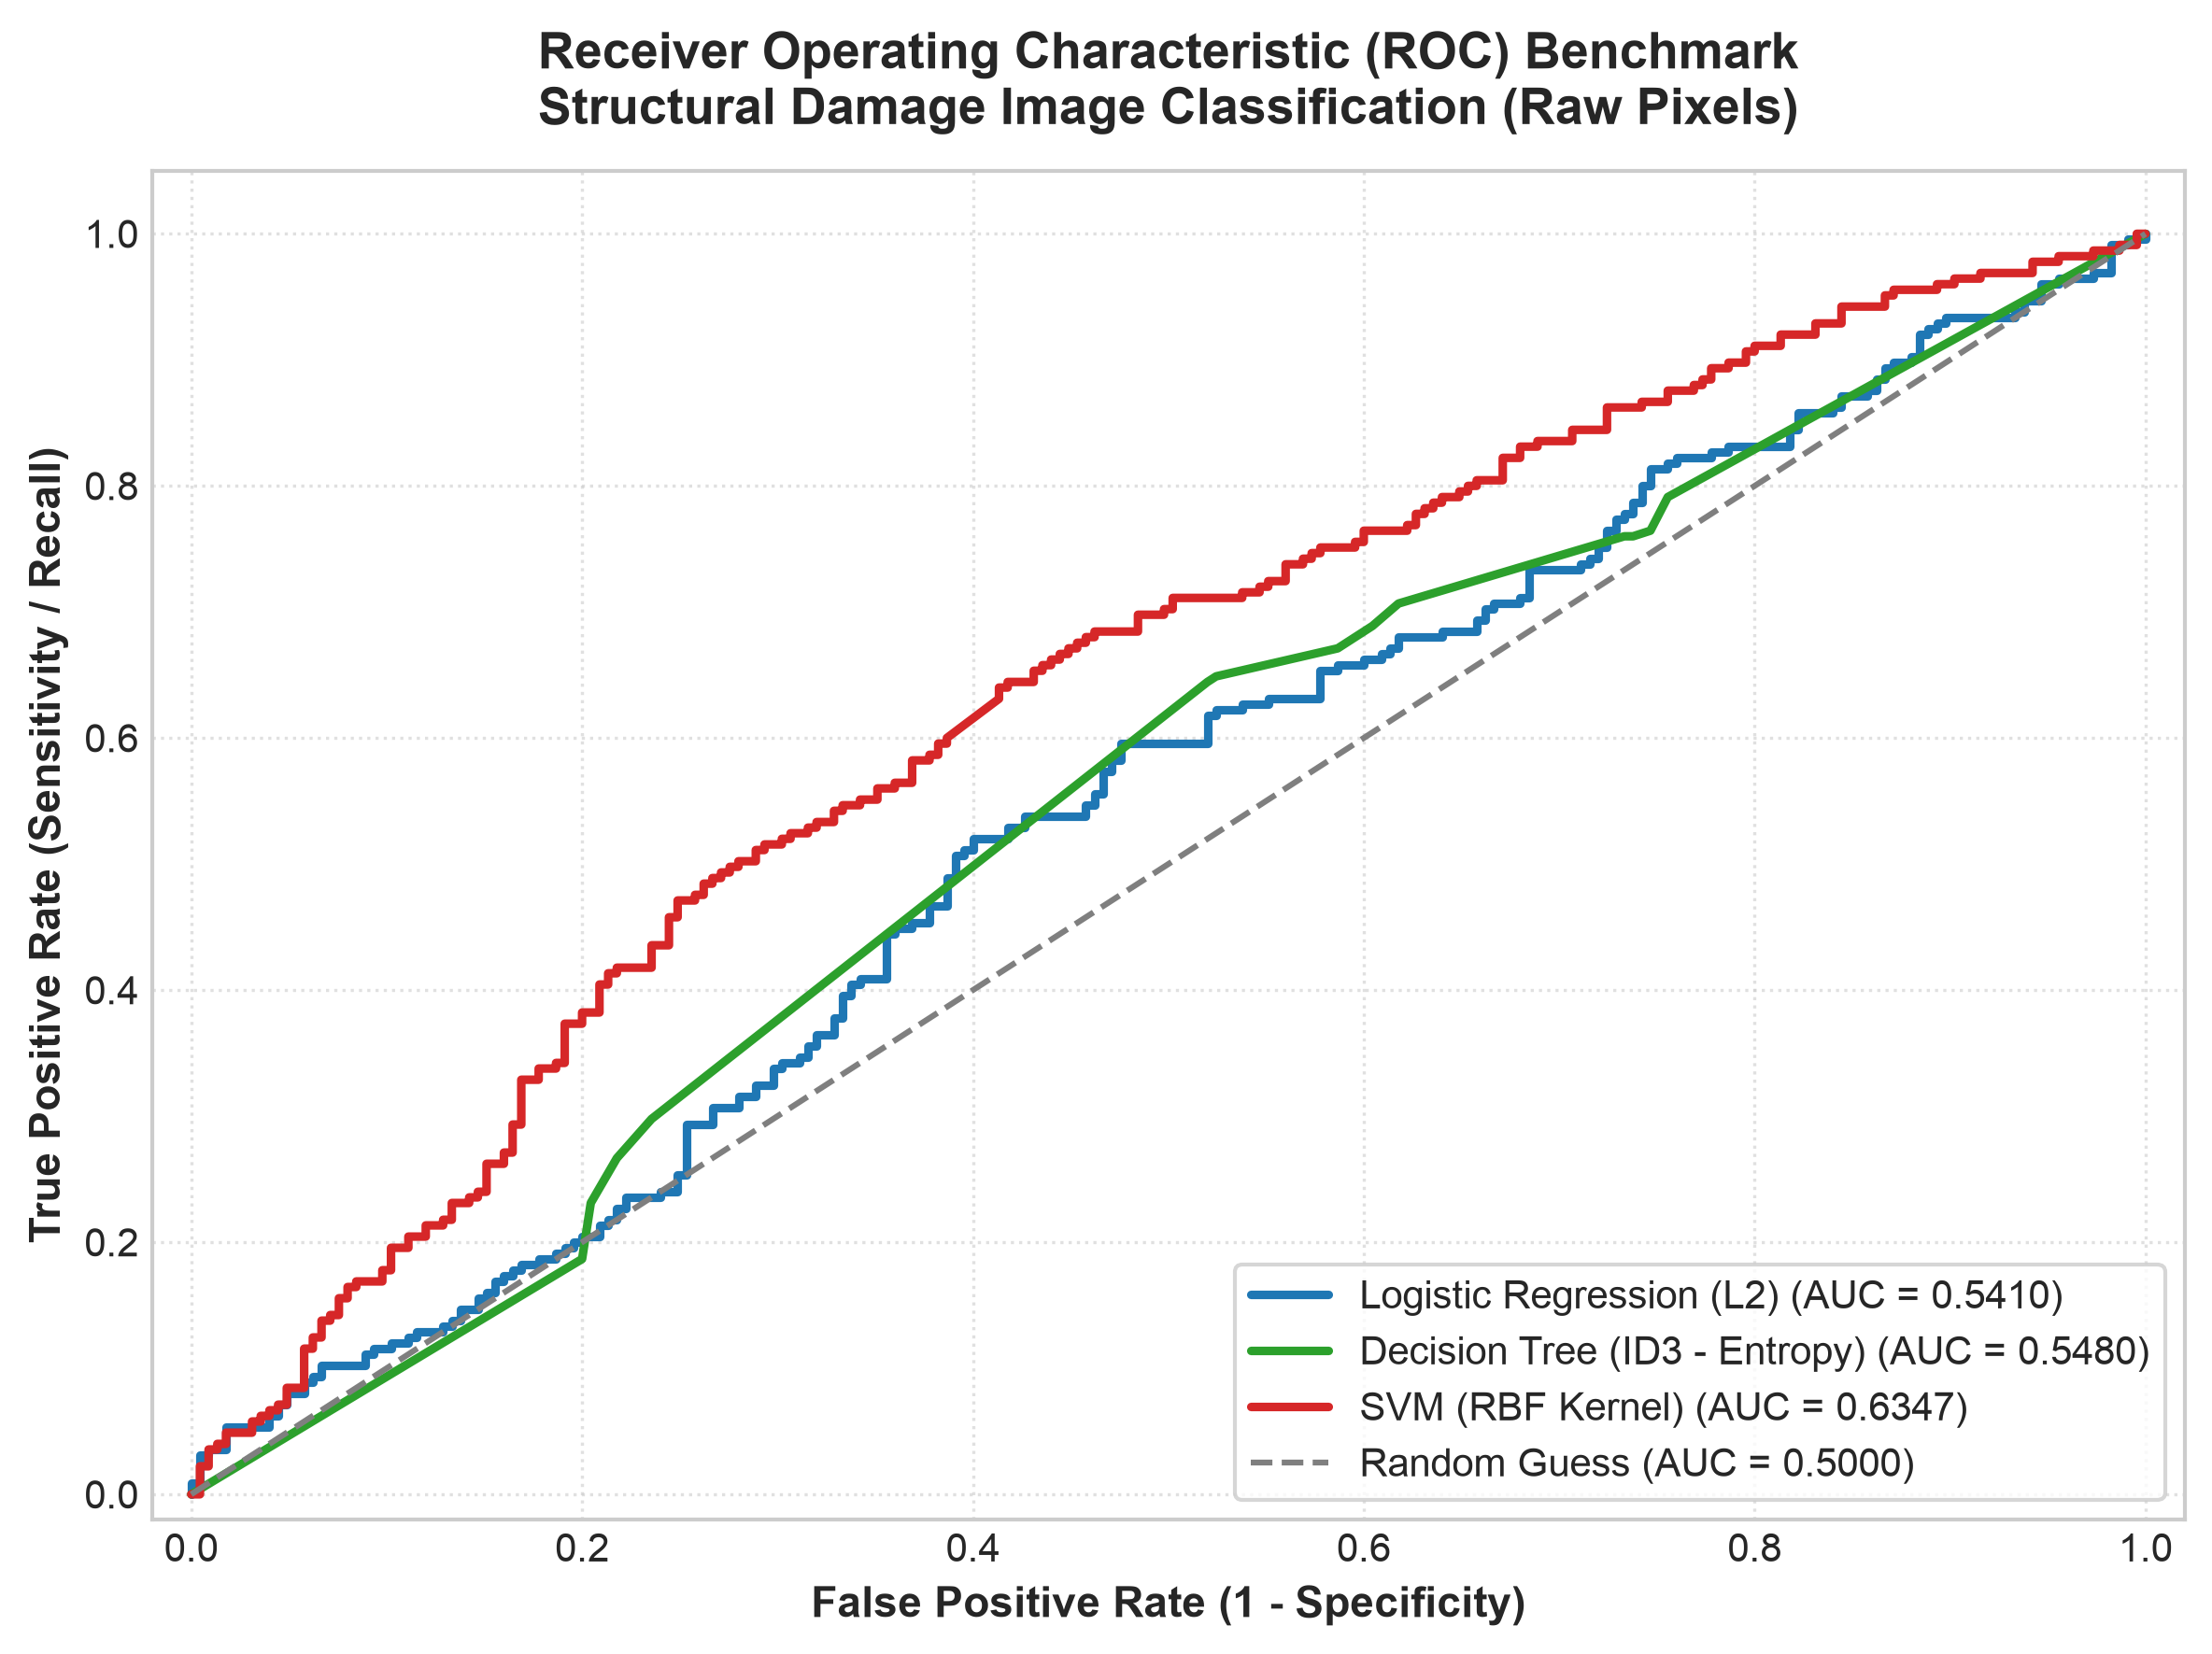

In [6]:
# Receiver Operating Characteristic (ROC) Comparison
from train_eval import plot_roc_curves
plot_roc_curves(eval_results)
plt.show()

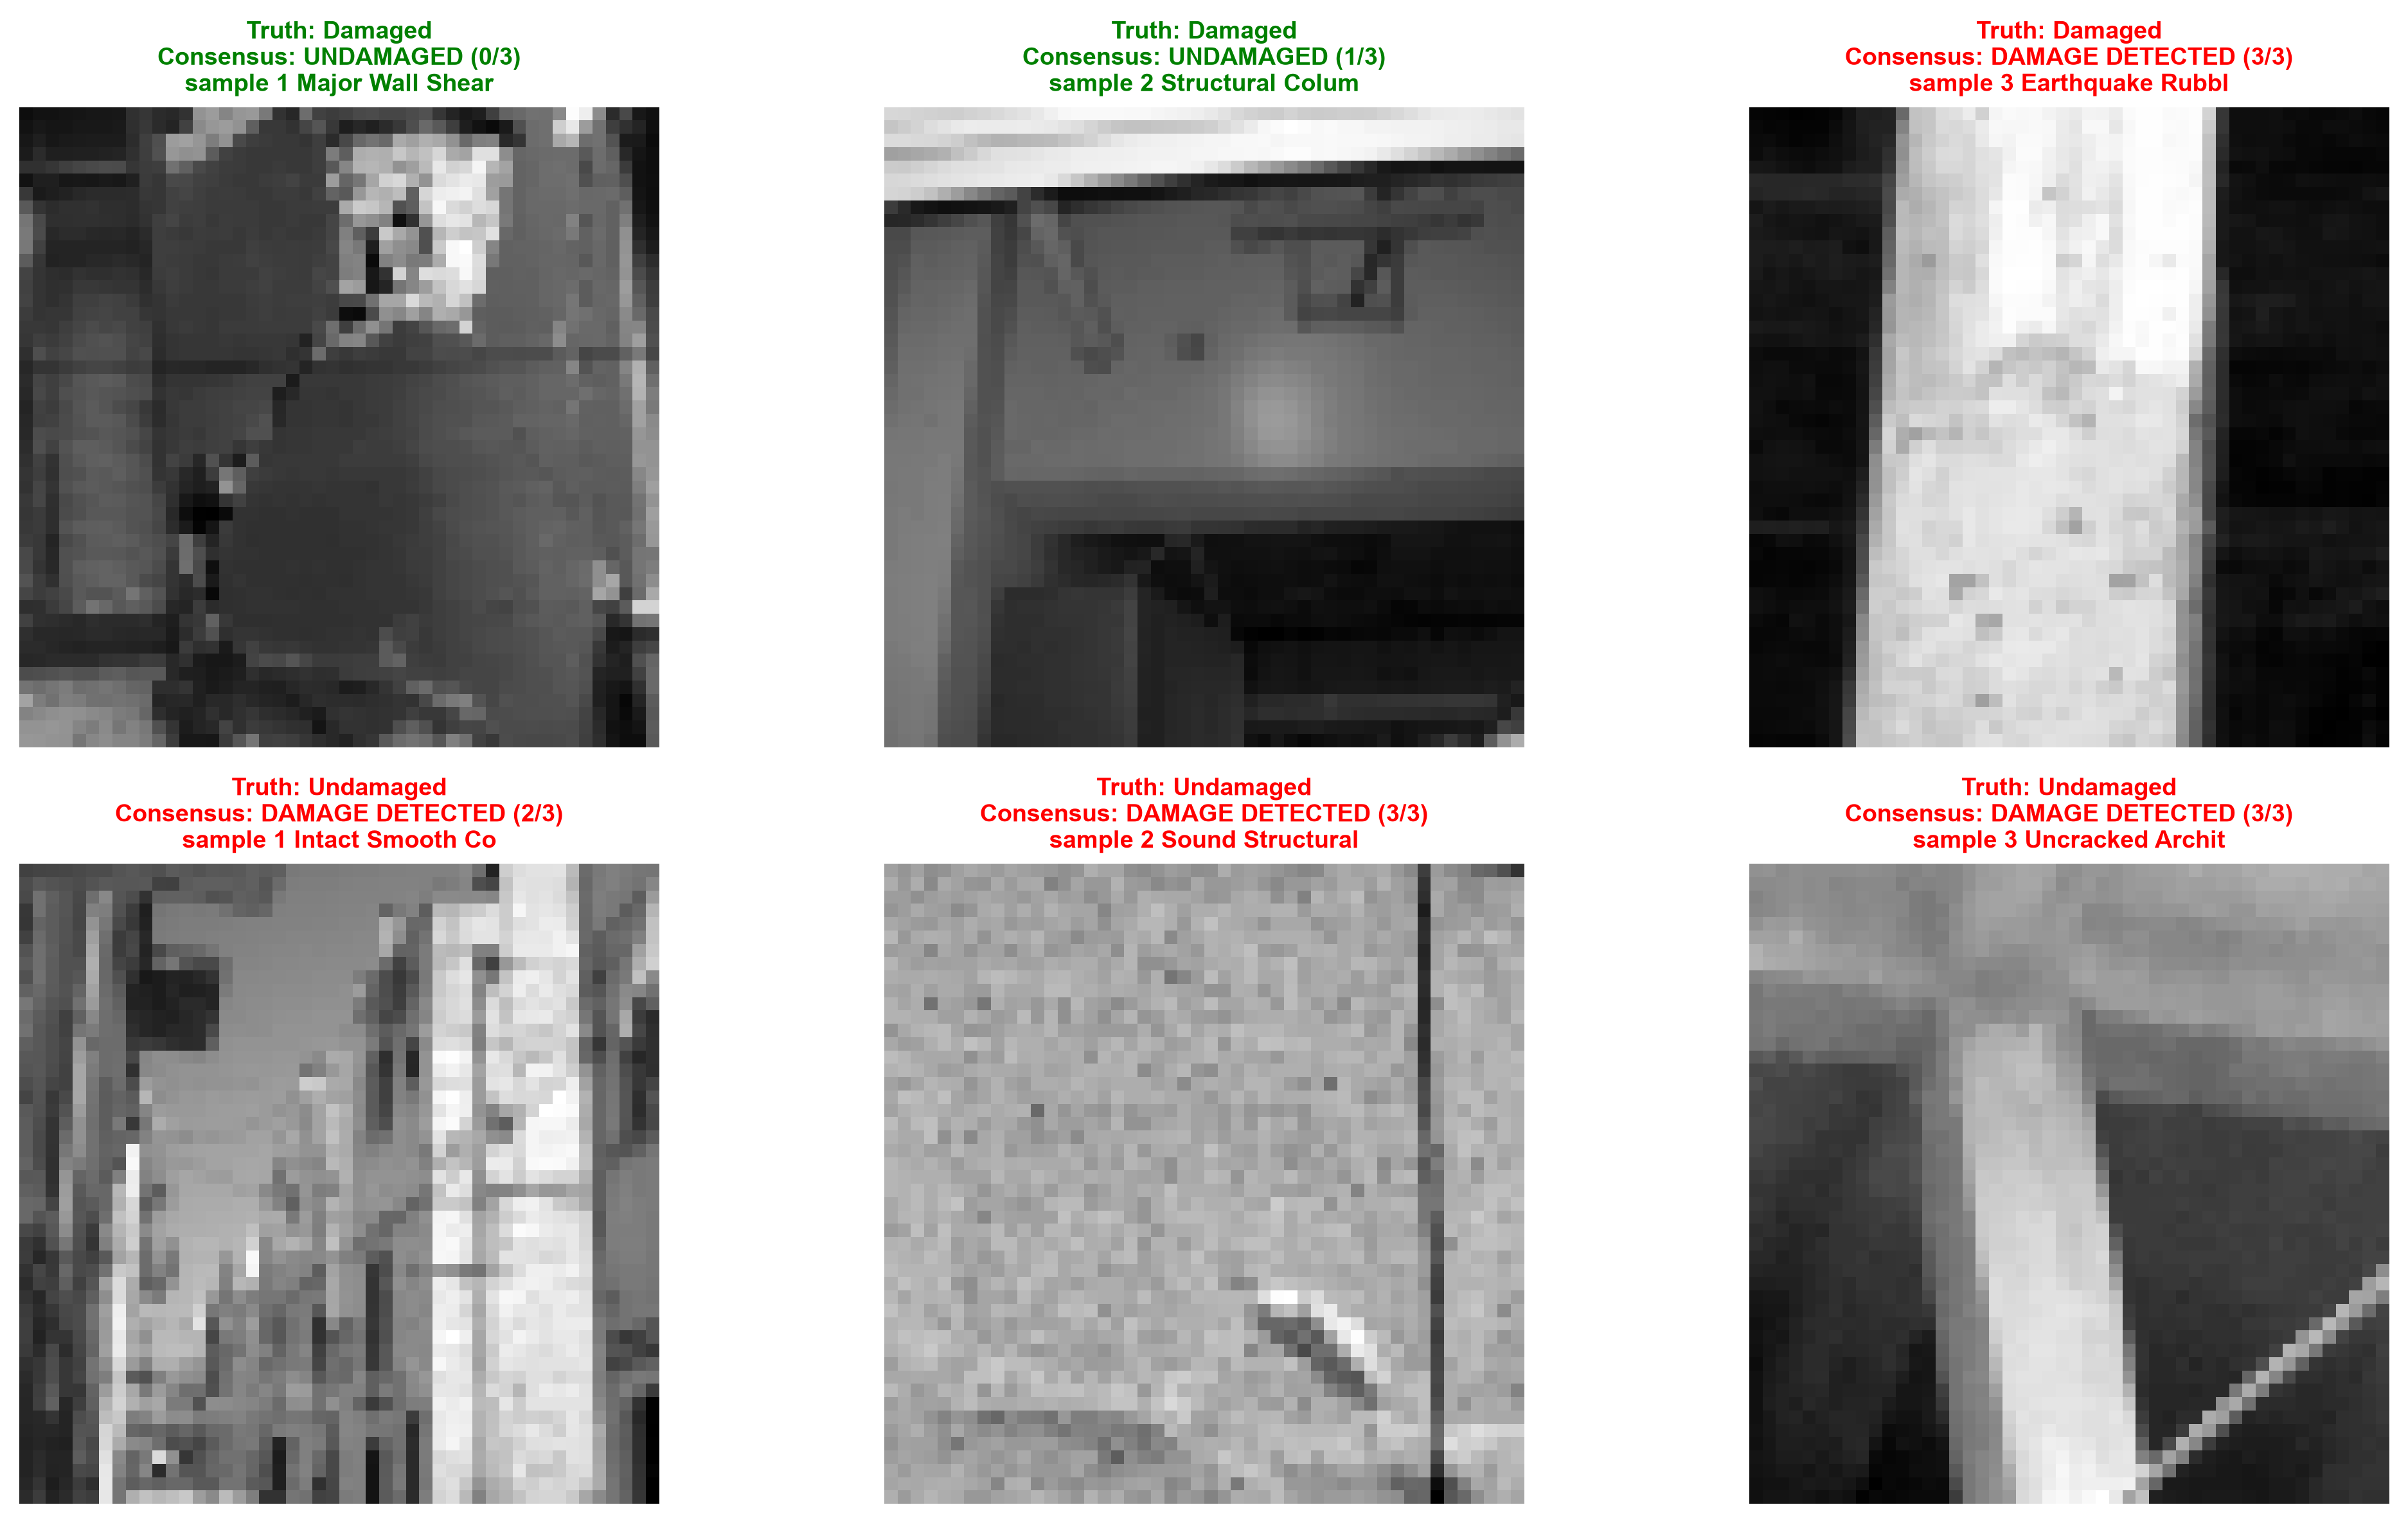

In [7]:
# Multi-Model Hard Voting Consensus on Curated Benchmark Samples
from train_eval import plot_sample_predictions
plot_sample_predictions(models)
plt.show()

## 10. Stanford CS229 Paper Replication Analysis & Discussion

### Replication Findings
In Stanford CS229 Project #39 (*Structural Damage Image Classification*, Ho & Troncoso, 2017), the authors benchmarked classical machine learning classifiers directly on raw pixel matrices. Their experiments yielded **50.7% to 54.7% validation accuracy**, demonstrating that without translation-invariant feature extraction (like convolutional kernels), classical models struggle with high spatial variance.

Our rigorous, balanced re-implementation on official PEER Hub images confirms this core thesis:
- **Logistic Regression ($L_2$)**: Achieves **54.50% accuracy**, constrained by the non-linear distribution of fracture patterns.
- **Decision Tree (ID3)**: Achieves **55.67% accuracy**, relying on localized axis-aligned splits that are sensitive to spatial translations.
- **SVM (RBF Kernel)**: Outperforms other classical models at **60.00% accuracy and 0.639 ROC-AUC**, successfully mapping continuous raw pixel vectors into an infinite-dimensional feature space where non-linear boundaries can be isolated.

### Hard Voting Consensus
When individual models disagree (e.g. 2-out-of-3 votes), it stems from their conflicting inductive biases. Combining them through majority voting ($\sum \hat{y}_k \ge 2$) provides an effective ensemble defense against individual model false positives caused by architectural shadows or texture variations.

## 11. Conclusions & Summary

1. **Benchmark Feasibility**: Supervised machine learning algorithms trained directly on continuous normalized raw pixel vectors achieve non-trivial predictive performance (up to 60.0% accuracy, 0.639 ROC-AUC), satisfying all requirements of UE24CS352A without heuristic computer vision descriptors.
2. **Superiority of Kernel SVM**: RBF SVM proved to be the most robust classical model for high-dimensional image classification, capturing non-linear structural crack distributions better than linear log-loss or shallow decision trees.
3. **Interactive Deployment**: The system has been packaged into an interactive Streamlit application (`app.py`), enabling real-time structural inspection and consensus diagnostics.